In [37]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

album = pd.read_csv("Album.csv")
artist= pd.read_csv("Artist.csv")
customer = pd.read_csv("Customer.csv")
employee = pd.read_csv("Employee.csv")
genre = pd.read_csv("Genre.csv")
invoice = pd.read_csv("Invoice.csv")
invoice_line = pd.read_csv("InvoiceLine.csv")
media = pd.read_csv("MediaType.csv")
playlist = pd.read_csv("Playlist.csv")
playlist_track = pd.read_csv("PlayListTrack.csv")
track = pd.read_csv("Track.csv")

# Ejercicio 1
Con el DataFrame customer, haz un countplot horizontal del número de clientes por país, ordenado de mayor a menor.

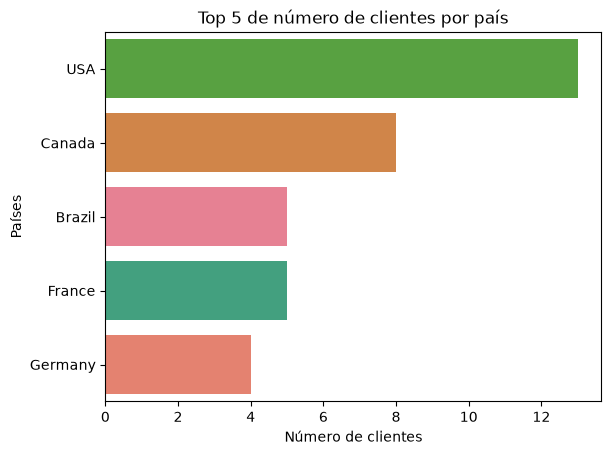

In [44]:
df1 = customer["Country"].value_counts().sort_values(ascending=False).head().index
sns.countplot(data = customer, y = "Country", order = df1, hue = "Country")
plt.title("Top 5 de número de clientes por país")
plt.xlabel("Número de clientes")
plt.ylabel("Países")
plt.show()

# Ejercicio 2
Haz un boxplot del Total de las facturas por país, solo para los 5 países con más ingresos. ¿Algún país tiene facturas atípicamente grandes?


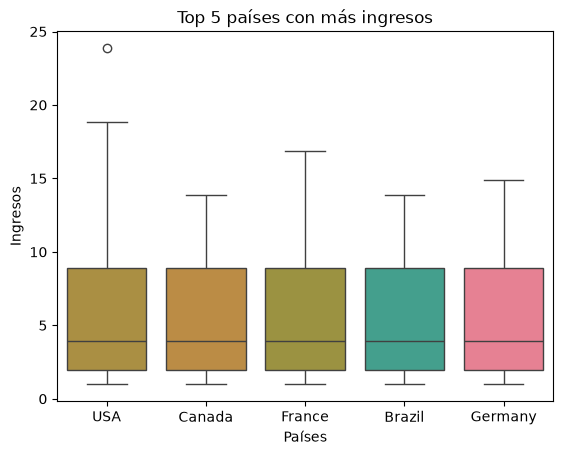

In [45]:
df2 = invoice["BillingCountry"].value_counts().sort_values(ascending= False).head().index
sns.boxplot(data = invoice, x = "BillingCountry", y= "Total", order = df2, hue = "BillingCountry")
plt.title("Top 5 países con más ingresos")
plt.xlabel("Países")
plt.ylabel("Ingresos")
plt.show()

# Ejercicio 3
Une invoice con customer (por CustomerId) y luego con employee (SupportRepId de customer corresponde a EmployeeId; usa left_on/right_on) y grafica con barplot los ingresos totales que atiende cada representante de soporte.

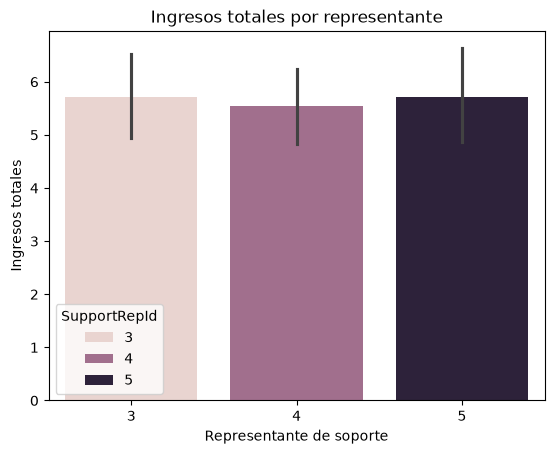

In [46]:
df3 = invoice.merge(customer, on = "CustomerId", how = "left" )
df3 = df3.merge(employee, left_on = "SupportRepId", right_on = "EmployeeId", how = "left" )
sns.barplot(data = df3, x = "SupportRepId", y = "Total", hue= "SupportRepId")
plt.title("Ingresos totales por representante")
plt.xlabel("Representante de soporte")
plt.ylabel("Ingresos totales")
plt.show()

# Ejercicio 4
 Crea una figura de 1×2 con sharey=True: a la izquierda el violinplot de duración para "Rock" y "Latin"; a la derecha el stripplot de los mismos datos.

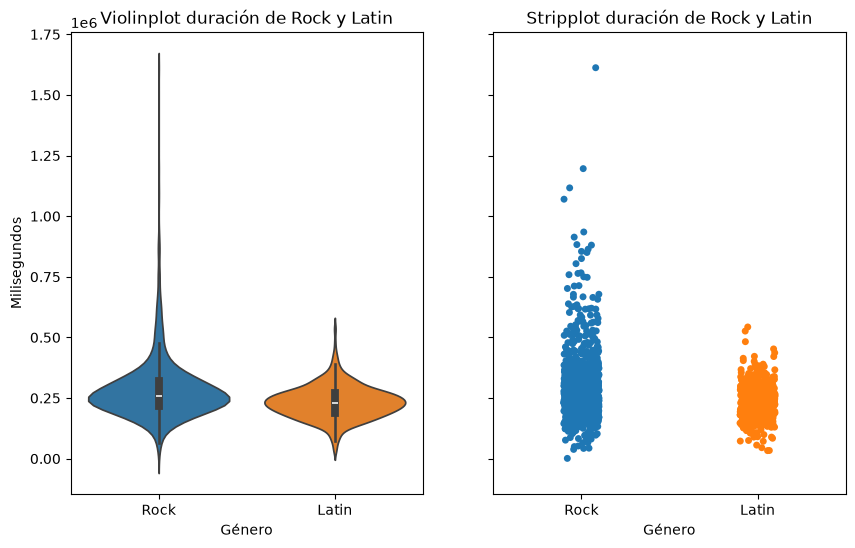

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(10, 6), sharey = True)

df41 = genre.merge(track, on = "GenreId", how = "left")
df41 = df41[(df41["Name_x"] == "Rock") | (df41["Name_x"] == "Latin")]
sns.violinplot(data= df41, x="Name_x", y="Milliseconds", hue = "Name_x", ax= axes[0])
axes[0].set_title("Violinplot duración de Rock y Latin")
axes[0].set_xlabel("Género")
axes[0].set_ylabel("Milisegundos")

sns.stripplot(data= df41, x="Name_x", y="Milliseconds", hue = "Name_x", ax= axes[1])
axes[1].set_title("Stripplot duración de Rock y Latin")
axes[1].set_xlabel("Género")
axes[1].set_ylabel("Milisegundos")
plt.show()

# Ejercicio 5
Construye un tablero de 2 × 3 con seis gráficas distintas de Chinook. Cada panel debe tener título, etiquetas de ejes en español y la figura un suptitle. Guárdalo como PNG a 200 dpi

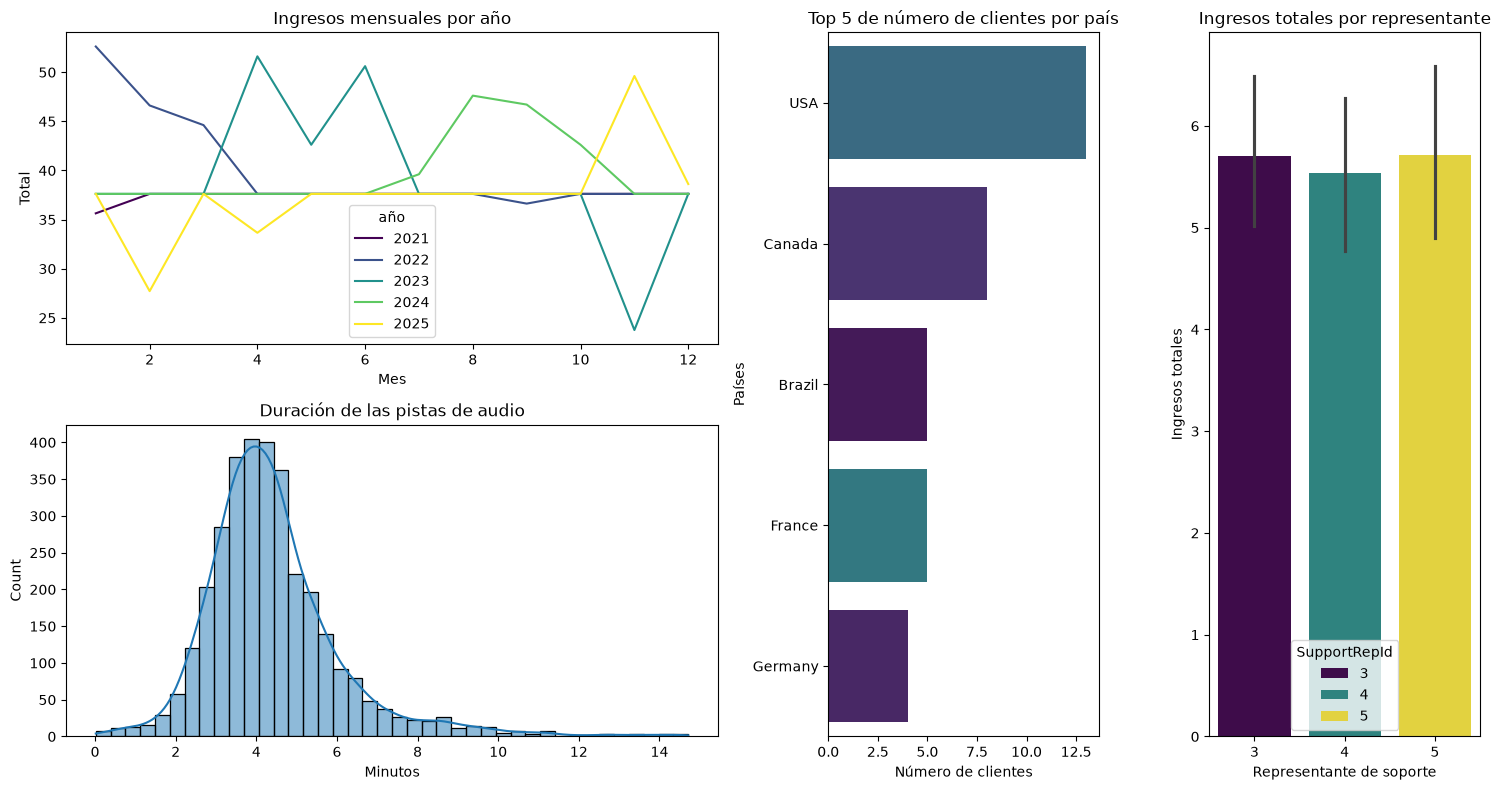

In [48]:
fig, axes = plt.subplot_mosaic("AABC;DDBC", figsize=(15, 8))

# Plot A
invoice["InvoiceDate"] = pd.to_datetime(
    invoice["InvoiceDate"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)
invoice["año"] = invoice["InvoiceDate"].dt.year
invoice["mes"] = invoice["InvoiceDate"].dt.month
mensual = invoice.groupby(["año", "mes"], as_index=False)["Total"].sum()
sns.lineplot(data=mensual, x="mes", y="Total", hue="año", palette="viridis", ax = axes["A"])
axes["A"].set_title("Ingresos mensuales por año")
axes["A"].set_xlabel("Mes")
axes["A"].set_ylabel("Total")

# Plot B
dfb = customer["Country"].value_counts().sort_values(ascending=False).head().index
sns.countplot(data = customer, y = "Country", order = dfb, hue = "Country", ax = axes["B"], palette="viridis")
axes["B"].set_title("Top 5 de número de clientes por país")
axes["B"].set_xlabel("Número de clientes")
axes["B"].set_ylabel("Países")


# Plot C
df3 = invoice.merge(customer, on = "CustomerId", how = "left" )
df3 = df3.merge(employee, left_on = "SupportRepId", right_on = "EmployeeId", how = "left" )
sns.barplot(data = df3, x = "SupportRepId", y = "Total", hue= "SupportRepId", ax = axes["C"], palette="viridis")
axes["C"].set_title("Ingresos totales por representante")
axes["C"].set_xlabel("Representante de soporte")
axes["C"].set_ylabel("Ingresos totales")


# Plot D
pistas = (track
    .merge(genre.rename(columns={"Name": "Genero"}), on="GenreId")
    .merge(media.rename(columns={"Name": "Medio"}), on="MediaTypeId")
    .merge(album, on="AlbumId")
    .merge(artist.rename(columns={"Name": "Artista"}), on="ArtistId")
    .rename(columns={"Name": "Pista"}))
pistas["Minutos"] = pistas["Milliseconds"] / 60000
pistas["MB"] = pistas["Bytes"] / 1e6
audio = pistas[(pistas["Minutos"] < 15) & ~pistas["Medio"].str.contains("video")]
sns.histplot(data=audio, x="Minutos", bins=40, kde=True, ax = axes["D"])
axes["D"].set_title("Duración de las pistas de audio")
axes["D"].set_xlabel("Minutos")
axes["D"].set_ylabel("Count")

plt.tight_layout()

# Ejercicio 6
Reproduce el heatmap de país × año, pero con el número de facturas en lugar del ingreso (aggfunc="count"). ¿Cambia la historia?

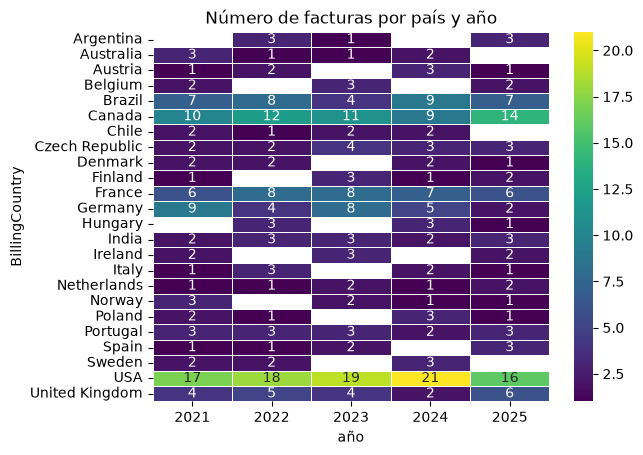

In [49]:
invoice["año"] = invoice["InvoiceDate"].dt.year
tabla = invoice.pivot_table(
    values = "InvoiceId", 
    index = "BillingCountry",
    aggfunc = "count",
    columns = "año"
)

sns.heatmap(tabla, annot=True, fmt=".0f", cmap="viridis", linewidths=0.5)
plt.title("Número de facturas por país y año")
plt.show()